# Phase 4.0 – Weather data: fetch and attach

The coach believes weather (temperature, wind, humidity, rain) affects the dogs. Before we can test that (Phase 4B), every competition day and every heat needs its weather. This notebook shows **where the weather comes from, how it is joined to the heats, and what the 2023 season looked like**. There is no analysis here yet.

**Source:** [Open-Meteo historical archive](https://open-meteo.com/en/docs/historical-weather-api). This is hourly *reanalysis* data: a weather model corrected with observations, on a grid of about 10 km. There is no weather station at the dog grounds, so this is the best consistent source for all 10 venues. Rules and counts are in `ANALYSIS_LOG.md` Step 3. The whole step is rebuilt by `scripts/run_phase4_weather.py`.

In [1]:
import pandas as pd
from IPython.display import display
from flyball import config, weather
from flyball.plots import phase4 as plots, style

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 1)
style.apply()

comps = pd.read_csv(config.PROCESSED / "competitions.csv")

## 1. Where were the competitions?

The sheet titles name the venue village only. Three names (Heroltice, Louňovice, Pláně) and one more found during checking (Blšany) exist more than once in the Czech Republic. Each was settled from the event's own pages: the organising club, the address of the ground, or a club's race report. The coordinates are fixed in `config.VENUES`, so every run uses the same points.

In [2]:
venues = pd.DataFrame([{"venue": k, "lat": v["lat"], "lon": v["lon"], "why this place": v["note"]}
                       for k, v in config.VENUES.items()])
display(venues)

,venue,lat,lon,why this place
0,Heroltice,49.3,16.4,"Heroltice, Brno-venkov district (near Tišnov): 'Happy Herolky' dog-sport ground, Herol..."
1,Žamberk,50.1,16.5,"Žamberk, Ústí nad Orlicí district (unique match)."
2,Blšany,50.2,13.5,"Blšany, Louny district: football ground, U Stadionu 10, 439 88 (grass pitch). Not Blša..."
3,Pláně,50.0,13.3,"Pláně, Plzeň-sever district: the airfield near Plzeň where M.E.D.'s Trophy is held."
4,Prostějov,49.5,17.1,"Prostějov, KK Prostějov club ground (unique match)."
5,Nové Město pod Smrkem,50.9,15.2,"Nové Město pod Smrkem, Liberec district (unique match)."
6,Louňovice,50.0,14.8,"Louňovice, Praha-východ district (near Mukařov). Not Louňovice pod Blaníkem."
7,Litomyšl,49.9,16.3,"Litomyšl, Svitavy district (unique match)."
8,Vodňany,49.1,14.2,"Vodňany, Strakonice district, as in the sheet title. flyball.cz files the event under ..."
9,Tápiószentmárton,47.3,19.7,"Tápiószentmárton, Pest county, Hungary (European Flyball Championship 2023)."


## 2. What was fetched

Each event needs **one request**: its days plus the day before, so we can tell whether the ground was wet from overnight rain. Two rings at the same venue share the weather. This gives 28 sheet-days, 22 venue-days and 11 requests. The raw answers are saved in `data/external/weather/` (committed to git), so the notebook runs offline and always shows the same numbers.

The weather model answers for its nearest grid point. The table shows how far that point is from the ground: every venue is within about 7 km.

In [3]:
plan = weather.fetch_plan(comps)
raw, downloaded = weather.fetch_all(plan)          # reads the cache; downloads only if missing
print(f"{len(plan)} requests, {downloaded} downloaded now")
display(weather.grid_points(plan, raw))

11 requests, 0 downloaded now


,fetch_id,venue,venue_lat,venue_lon,grid_lat,grid_lon,grid_elevation_m,timezone,grid_distance_km
0,heroltice_2023-04-21_2023-04-23,Heroltice,49.3,16.4,49.3,16.4,296.0,Europe/Prague,3.6
1,zamberk_2023-05-05_2023-05-07,Žamberk,50.1,16.5,50.1,16.5,424.0,Europe/Prague,3.8
2,blsany_2023-05-19_2023-05-21,Blšany,50.2,13.5,50.2,13.4,284.0,Europe/Prague,3.8
3,plane_2023-06-09_2023-06-11,Pláně,50.0,13.3,49.9,13.3,527.0,Europe/Prague,1.4
4,prostejov_2023-06-23_2023-06-25,Prostějov,49.5,17.1,49.5,17.1,229.0,Europe/Prague,6.7
5,nove_mesto_pod_smrkem_2023-06-30_2023-07-02,Nové Město pod Smrkem,50.9,15.2,50.9,15.3,467.0,Europe/Prague,2.8
6,lounovice_2023-07-14_2023-07-16,Louňovice,50.0,14.8,50.0,14.8,434.0,Europe/Prague,3.9
7,blsany_2023-09-01_2023-09-03,Blšany,50.2,13.5,50.2,13.4,284.0,Europe/Prague,3.8
8,litomysl_2023-09-15_2023-09-17,Litomyšl,49.9,16.3,49.9,16.3,334.0,Europe/Prague,2.7
9,vodnany_2023-10-13_2023-10-15,Vodňany,49.1,14.2,49.2,14.2,406.0,Europe/Prague,3.3


## 3. How weather is attached to a heat

Every heat has a clock time (`heat_time`), so it gets the weather **at the minute it ran**, not a daily average:

- **Temperature, humidity, wind, cloud** are values at each full hour. A heat at 10:30 gets the value halfway between 10:00 and 11:00.
- **Rain, gusts and sunshine** are totals or maxima *over an hour*. A heat at 10:30 gets the 10:00–11:00 block.
- **Wet ground:** the rain in the last 3 h and in the last 24 h before the heat.

All **4,336 heats** are matched, with no gaps. For the analysis, `weather.attach(runs, heat_wx)` adds these columns to the heats or runs tables.

In [4]:
heat_wx = pd.read_parquet(config.PROCESSED / "heat_weather.parquet")
print(f"heats with weather: {heat_wx['temp_c'].notna().sum()} of {len(heat_wx)}")
display(heat_wx[heat_wx["comp_day_id"] == "S08-D1"].iloc[::40, :12])

heats with weather: 4336 of 4336


,heat_id,venue,heat_time,temp_c,apparent_temp_c,humidity_pct,dew_point_c,cloud_pct,wind_ms,wind_dir_deg,hour_block,precip_mm
2087,2087,Louňovice,2023-07-15 08:57:13,24.0,24.4,52.6,13.5,4.6e-02,1.3,128.9,2023-07-15 09:00:00,0.0
2127,2127,Louňovice,2023-07-15 10:40:50,28.0,28.0,37.2,12.1,1.0e+00,2.5,162.5,2023-07-15 11:00:00,0.0
2167,2167,Louňovice,2023-07-15 12:20:52,30.5,30.8,31.6,11.7,5.2e+00,3.2,175.4,2023-07-15 13:00:00,0.0
2207,2207,Louňovice,2023-07-15 16:42:22,33.5,32.8,27.7,12.2,2.4e+01,3.4,163.9,2023-07-15 17:00:00,0.0
2247,2247,Louňovice,2023-07-15 18:21:50,32.9,32.8,31.3,13.6,8.2e+00,2.5,164.4,2023-07-15 19:00:00,0.0


## 4. The 2023 season's weather

One row per sheet-day, summarised over its **racing hours** (from the first heat to the last).

In [5]:
day = pd.read_csv(config.PROCESSED / "weather_day.csv")
cols = ["comp_day_id", "competition", "date", "race_start", "race_end", "temp_min_c", "temp_max_c",
        "humidity_mean_pct", "wind_mean_ms", "gust_max_ms", "precip_total_mm", "rain_hours",
        "precip_24h_before_mm", "cloud_mean_pct"]
display(day[cols])

,comp_day_id,competition,date,race_start,race_end,temp_min_c,temp_max_c,humidity_mean_pct,wind_mean_ms,gust_max_ms,precip_total_mm,rain_hours,precip_24h_before_mm,cloud_mean_pct
0,S01-D1,Hanácké škvarek,2023-04-22,10:00,18:00,15.0,19.5,44.7,3.2,9.3,0.0,0,0.0,20.2
1,S01-D2,Hanácké škvarek,2023-04-23,09:00,14:00,12.3,17.4,66.0,2.1,6.8,0.0,0,0.0,99.8
2,S02-D1,Eager´s Cup,2023-05-06,09:00,19:00,10.6,16.4,73.4,3.9,11.5,3.0,5,1.1,81.0
3,S02-D2,Eager´s Cup,2023-05-07,08:00,19:00,7.0,10.5,75.4,5.0,11.4,0.0,0,3.7,95.9
4,S03-D1,Eager´s Cup,2023-05-06,09:00,19:00,10.6,16.4,73.4,3.9,11.5,3.0,5,1.1,81.0
5,S03-D2,Eager´s Cup,2023-05-07,08:00,19:00,7.0,10.5,75.4,5.0,11.4,0.0,0,3.7,95.9
6,S04-D1,Flyvaryors turnaj,2023-05-20,09:00,18:00,13.0,22.6,59.2,4.9,11.9,1.9,2,0.0,79.8
7,S04-D2,Flyvaryors turnaj,2023-05-21,08:00,17:00,14.9,24.1,62.0,3.2,9.4,0.1,1,1.9,85.6
8,S05-D1,MED's Trophy,2023-06-10,09:00,17:00,18.6,22.6,63.0,4.7,11.4,2.4,6,3.0,48.8
9,S05-D2,MED's Trophy,2023-06-11,08:00,17:00,16.7,22.5,48.6,4.6,11.0,0.0,0,2.4,19.6


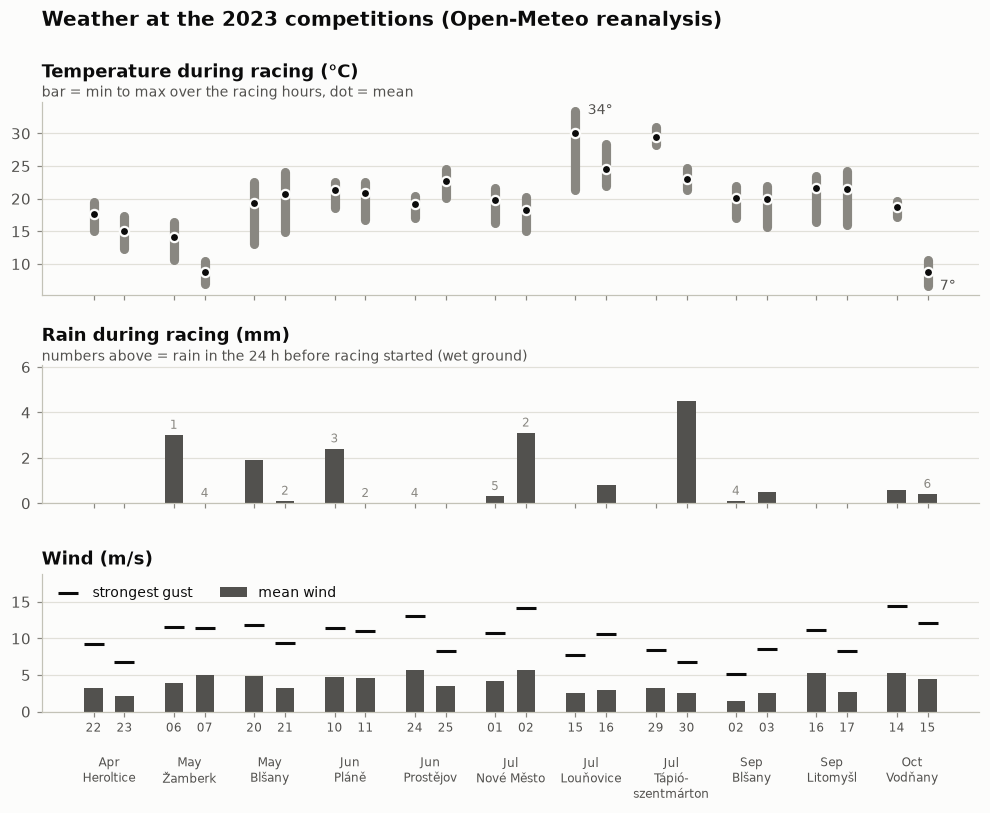

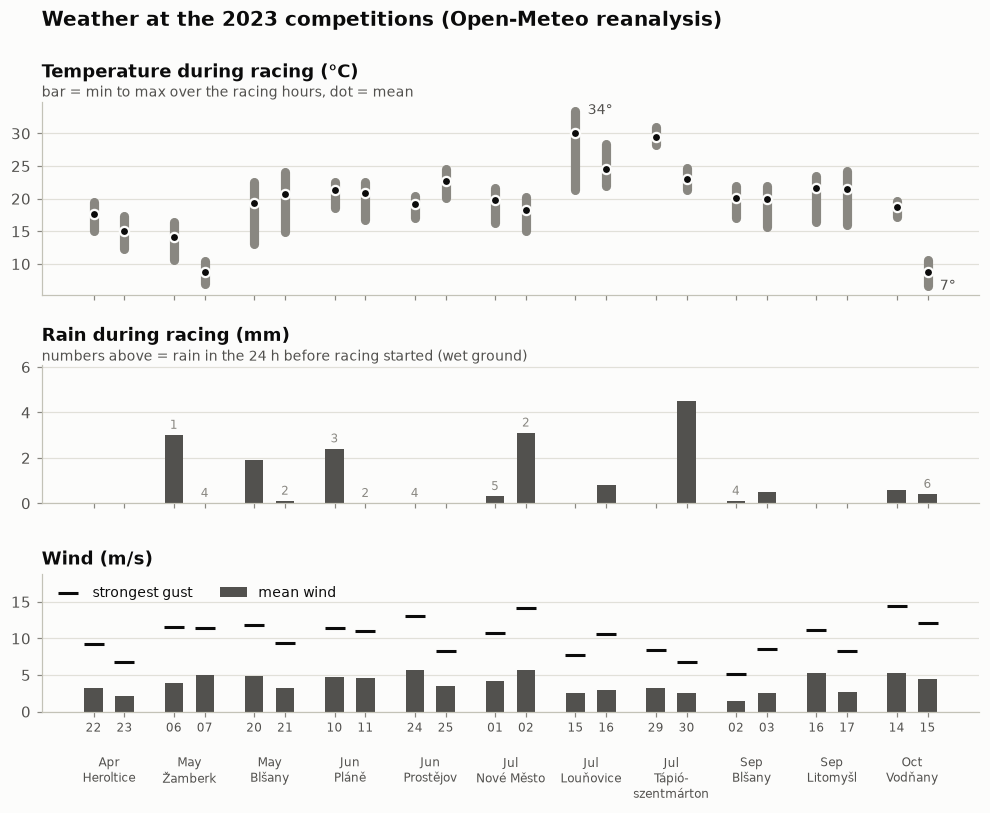

In [6]:
plots.weather_strip(day)

**What this shows:**
- **Temperature varies a lot:** from about 7 °C (Vodňany, 15 Oct, after a cold front overnight) to 33–34 °C (Louňovice, 15 Jul, heatwave). A spread like this is what we need to test the coach's heat hypothesis.
- **Rain is rare and light:** heavy rain never fell during racing. The wettest days had 3–4.5 mm spread over several hours (Žamberk 6 May, Nové Město 2 Jul, EFC 30 Jul). Rain will be a weak signal.
- **Wind** is moderate throughout: mean 1.4–5.7 m/s, with gusts up to 14.5 m/s.
- **Same weekend, different weather:** several events changed sharply between Saturday and Sunday (Žamberk, Louňovice, EFC, Vodňany). Within a competition, this lets us separate the weather from the venue.

## 5. How much to trust it (spot-check and limits)

The reanalysis was compared with the nearest official weather stations, using their hourly records from Meteostat:

| Venue (station) | Hourly temperature agreement | Daily maximum, model vs station |
|---|---|---|
| Heroltice (Brno-Tuřany, 27 km) | r = 0.94, mean difference 1.3 °C | 19.5 vs 19.7 °C, 18.2 vs 19.6 °C |
| Louňovice (Praha-Ruzyně, 38 km) | r = 0.93, 1.8 °C | 33.5 vs 35.2 °C, 28.4 vs 27.0 °C |
| Vodňany (Temelín, 13 km) | r = 0.98, 1.1 °C | 19.7 vs 19.8 °C, 10.6 vs 8.9 °C |
| Tápiószentmárton (Budapest airport, 44 km) | r = 0.97, 0.6 °C | 31.0 vs 30.7 °C, 24.7 vs 25.4 °C |

**Temperature is reliable. Humidity and wind are good on most days, but can be off by up to about 15 points and 2 m/s. Rain is the weakest variable.** Summer showers are local, and the model tends to spread light rain over a wider area. Treat rain as "dry vs wet day", not as exact millimetres.

**Not known:** whether any event was indoors, the direction of the lanes (so wind can't be split into head- and tailwind), and the ground surface (only Blšany is confirmed as grass).